# Analysis of times it takes for packets to reach from NIC to Application in a regular networking app using Linux socket API.

## Experiment setup

Trading day: *30 Jan 2019*

High packet rate time window: *15:59:59–16:00:01*

Low packet rate time window: *14:59:00–15:00:03*

We will use Linux socket API to send and receive packets. NIC is hardware timestamping capable, which gives us the ability to measure the time it takes for packets to reach from NIC to Application. We conduct 15 runs for every system configuration. The configuration space is comprised of choices on OS settings (Default/Low latency tuned) and replay duration (2s and 63s), so 4 configurations in total. Note that for every configuration, the number of packets sent is approximately the same $\approx 18000$, so replay duration directly translates to higher and lower packet rates.

### Imports

In [1]:
import re

import itertools
import numpy as np
from pathlib import Path
from enum import Enum, auto
from analysis.utils import report_metrics, generate_percentiles, plot_percentiles

### Load data

In [2]:
class OS(Enum):
    DEFAULT = auto()
    LOW_LATENCY = auto()
class PacketRate(Enum):
    HIGH = auto()
    LOW = auto()
class TsType(Enum):
    NIC = auto()
    APP = auto()

In [3]:
def natural_sort_key(path):
    return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', path.name)]

In [4]:
kernel_latency_folder = '/home/illia-derevianko/Projects/nanoparser/analysis/kernel_latency'
tuning_folders = {OS.LOW_LATENCY: 'tuning', OS.DEFAULT: 'no_tuning'}
packet_rate_folders = {PacketRate.HIGH: 'high_packet_rate', PacketRate.LOW: 'low_packet_rate'}
filename_pattern = {TsType.NIC: r'^rx_times\d+', TsType.APP: r'^receive_app_times\d+'}

data: dict[tuple[OS, PacketRate, TsType], np.ndarray] = dict()

for config in itertools.product(OS, PacketRate, TsType):
    os_type, packet_rate, ts_type = config
    dir_path = Path(kernel_latency_folder) / tuning_folders[os_type] / packet_rate_folders[packet_rate]
    pattern = re.compile(filename_pattern[ts_type])
    target_files = sorted([f for f in dir_path.iterdir() if f.is_file() and pattern.match(f.name)], key=natural_sort_key)

    if target_files:
        print(f"Loading {len(target_files)} files for {os_type.name}, {packet_rate.name}, {ts_type.name}")
        file_arrays = [np.fromfile(f, dtype=np.uint64) for f in target_files]
        data[config] = np.array(file_arrays)
    else:
        print(f"Warning: No match found for {os_type.name}, {packet_rate.name}, {ts_type.name} in {dir_path}")

Loading 15 files for DEFAULT, HIGH, NIC
Loading 15 files for DEFAULT, HIGH, APP
Loading 15 files for DEFAULT, LOW, NIC
Loading 15 files for DEFAULT, LOW, APP
Loading 15 files for LOW_LATENCY, HIGH, NIC
Loading 15 files for LOW_LATENCY, HIGH, APP
Loading 15 files for LOW_LATENCY, LOW, NIC
Loading 15 files for LOW_LATENCY, LOW, APP


In [5]:
def timestamp_diff(minuend, subtrahend):
    assert minuend.shape == subtrahend.shape
    assert minuend.dtype == subtrahend.dtype
    assert (minuend > subtrahend).all()
    return minuend - subtrahend

## Comparison (OS tuned for low latency vs default)

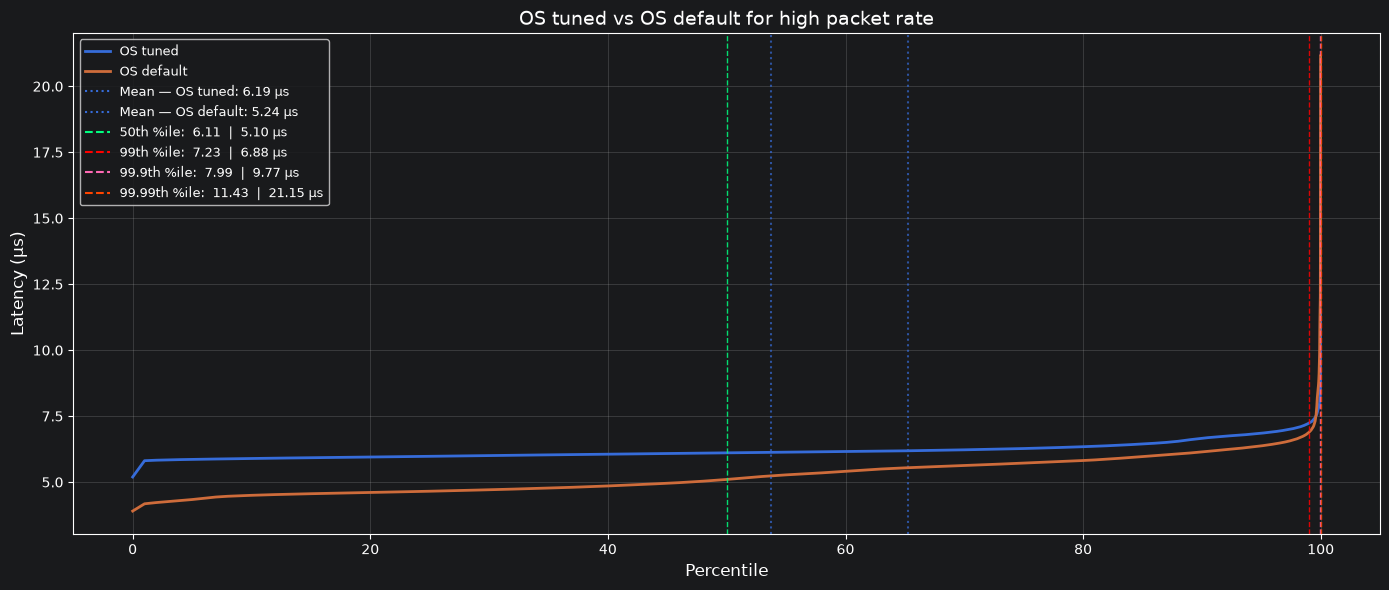

In [6]:
latencies_tuned_high_rate = timestamp_diff(data[(OS.LOW_LATENCY, PacketRate.HIGH, TsType.APP)],
                   data[(OS.LOW_LATENCY, PacketRate.HIGH, TsType.NIC)]).flatten() / 1000

latencies_default_high_rate = timestamp_diff(data[(OS.DEFAULT, PacketRate.HIGH, TsType.APP)],
                     data[(OS.DEFAULT, PacketRate.HIGH, TsType.NIC)]).flatten() / 1000

plot_percentiles(
    (latencies_tuned_high_rate, "OS tuned"),
    (latencies_default_high_rate, "OS default"),
    percentiles=generate_percentiles(99.99),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="OS tuned vs OS default for high packet rate")

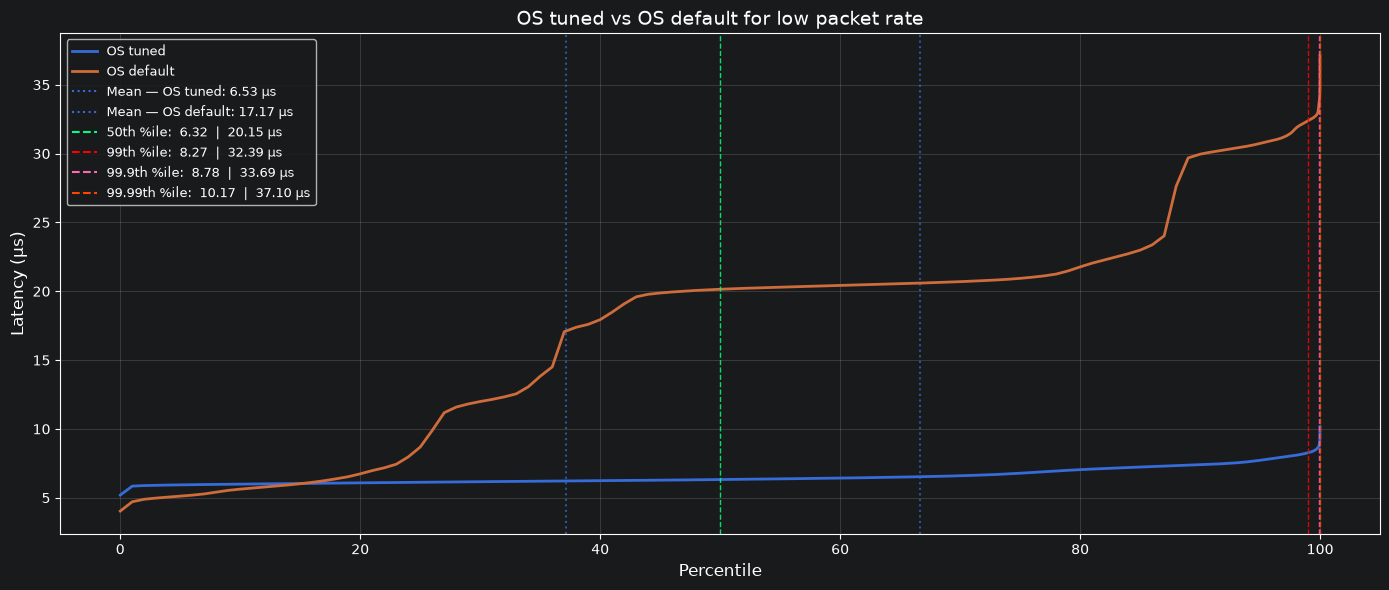

In [7]:
latencies_tuned_low_rate = timestamp_diff(data[(OS.LOW_LATENCY, PacketRate.LOW, TsType.APP)],
                            data[(OS.LOW_LATENCY, PacketRate.LOW, TsType.NIC)]).flatten() / 1000
latencies_default_low_rate = timestamp_diff(data[(OS.DEFAULT, PacketRate.LOW, TsType.APP)],
                              data[(OS.DEFAULT, PacketRate.LOW, TsType.NIC)]).flatten() / 1000

plot_percentiles(
    (latencies_tuned_low_rate, "OS tuned"),
    (latencies_default_low_rate, "OS default"),
    percentiles=generate_percentiles(99.99),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="OS tuned vs OS default for low packet rate")

## Comparison (Low vs high packet rate)

(282240,)


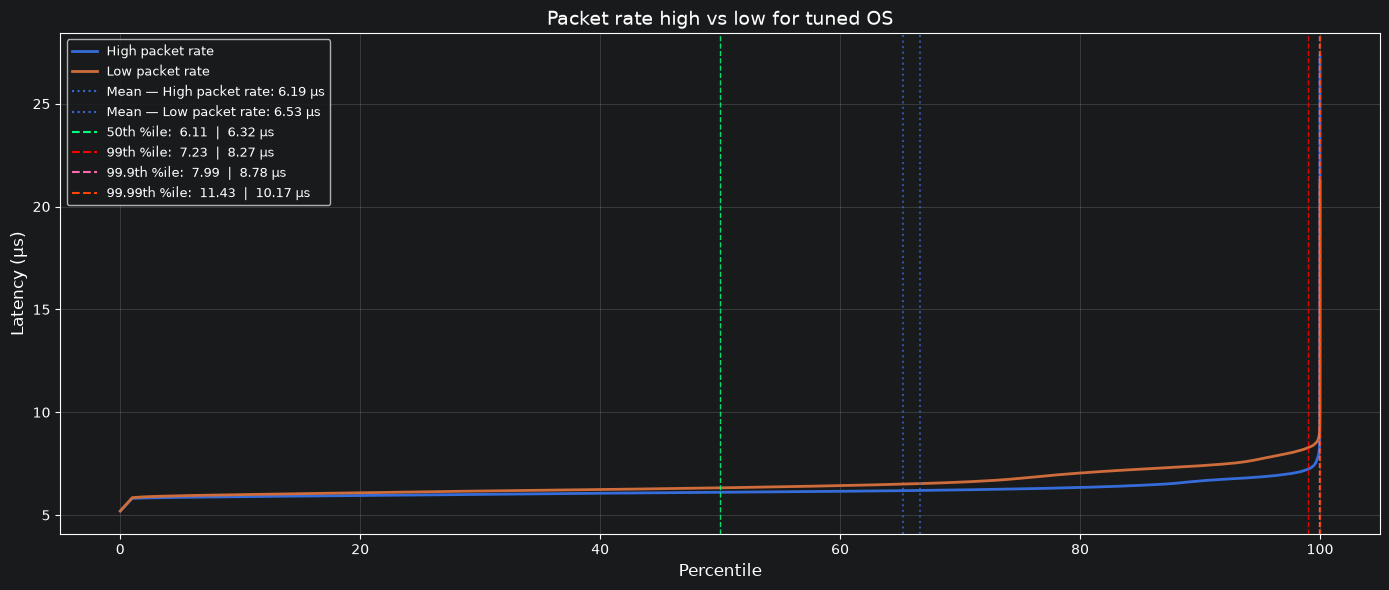

In [8]:
plot_percentiles(
    (latencies_tuned_high_rate, "High packet rate"),
    (latencies_tuned_low_rate, "Low packet rate"),
    percentiles=generate_percentiles(100),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="Packet rate high vs low for tuned OS")

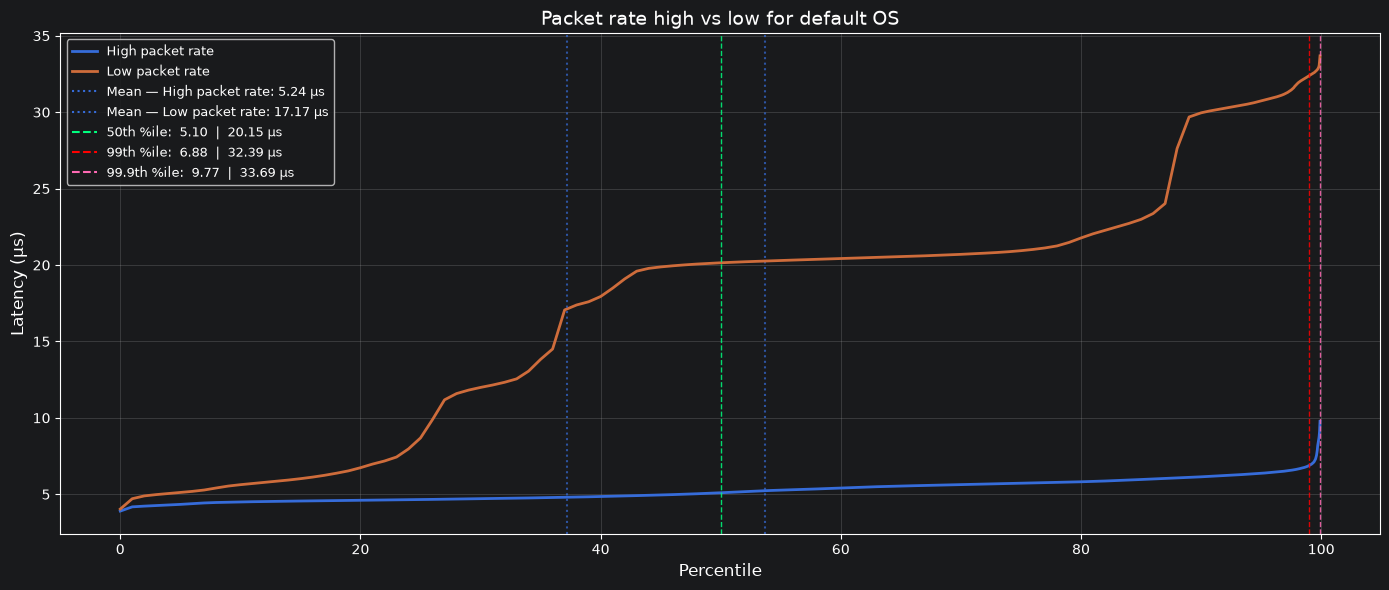

In [9]:
plot_percentiles(
    (latencies_default_high_rate, "High packet rate"),
    (latencies_default_low_rate, "Low packet rate"),
    percentiles=generate_percentiles(99.9),
    xlabel="Percentile",
    ylabel="Latency (µs)",
    title="Packet rate high vs low for default OS")

## Summary tuned OS

In [10]:
report_metrics(latencies_tuned_high_rate, "Tuned OS high packet rate")
report_metrics(latencies_tuned_low_rate, "Tuned OS low packet rate")

=== Tuned OS high packet rate ===
Count     : 282,240
Min       : 5.194
Max       : 27.325
Mean      : 6.187
Std Dev   : 0.340
P50 (Med) : 6.109
P90       : 6.661
P99       : 7.233
P99.9     : 7.988
P99.99    : 11.430

=== Tuned OS low packet rate ===
Count     : 280,740
Min       : 5.197
Max       : 21.231
Mean      : 6.529
Std Dev   : 0.583
P50 (Med) : 6.323
P90       : 7.396
P99       : 8.274
P99.9     : 8.779
P99.99    : 10.166



## Summary default OS

todo: absolute min/max, grand mean, polled variance, mean and std of tails
plot chronological stability

In [11]:
report_metrics(latencies_default_high_rate, "Default OS high packet rate")
report_metrics(latencies_default_low_rate, "Default OS low packet rate")

=== Default OS high packet rate ===
Count     : 282,240
Min       : 3.902
Max       : 66.376
Mean      : 5.235
Std Dev   : 0.809
P50 (Med) : 5.100
P90       : 6.143
P99       : 6.883
P99.9     : 9.774
P99.99    : 21.152

=== Default OS low packet rate ===
Count     : 280,740
Min       : 4.035
Max       : 63.016
Mean      : 17.171
Std Dev   : 8.010
P50 (Med) : 20.147
P90       : 29.959
P99       : 32.390
P99.9     : 33.685
P99.99    : 37.099



## Summary

The advantages of using a tuned kernel are clear and significant. Perhaps counterintuitively, the difference matters for larger inter-arrival packet gaps. One would expect that a higher packet rate would put higher pressure on the kernel and lead to higher latencies. However, in reality the situation is the opposite – the mean for the untuned OS 5.235$\mu s$ is lower compared to the tuned one of 6.187$\mu s$. Moreover, the results for the untuned version remain better all the way up to the 99th percentile. If packets arrived at such a high rate throughout the whole trading day, the given OS tuning would not be beneficial but if anything, would even slightly degrade the performance.

The landscape changes significantly for quieter periods that better represent a trading day than the second after market close. Here, the performance in the untuned environment starts rapidly deteriorating as early as at the 20th percentile. At the 99th percentile, while the tuned version's latency stays relatively close to the median at 8.274$\mu s$, the untuned version climbs all the way to 32.390$\mu s$. Remarkably, the highest latency recorded in the tuned environment (21.231 $\mu s$) is comparable to the median in the untuned environment (20.147 $\mu s$).

Although pinpointing which configuration change carries the greatest impact is beyond the scope of this analysis, it is clear that this tuning is necessary to achieve stable performance and avoid latency spikes. Most importantly, the tuned version shows nearly identical results for variable packet rates which provide the evidence that the system stays stable independently of the data it processes.

## Appendix
System tuning
BIOS: disable SMT, disable frequency boost

Kernel: Ubuntu realtime
```bash
# In /etc/default/grub
GRUB_CMDLINE_LINUX_DEFAULT="quiet splash amd_pstate=passive mitigations=off nowatchdog kthread_cpus=0-4 nohz nohz_full=5 isolcpus=domain,5 rcu_nocbs=5 irqaffinity=0-4 rcu_nocb_poll nosoftlockup"
# And run
sudo update-grub
```
```bash
cat /proc/interrupts | grep enp1s0f1
for i in {98..103}; do # 6 IRQs as given by cat /proc/interrupts | grep enp1s0f1
    echo 5 | sudo tee /proc/irq/$i/smp_affinity_list
done

echo performance | sudo tee /sys/devices/system/cpu/cpu5/cpufreq/energy_performance_preference
for f in /sys/bus/workqueue/devices/*/cpumask; do
    echo 1f | sudo tee $f
done
echo -1 | sudo tee /proc/sys/kernel/sched_rt_runtime_us
echo performance | sudo tee /sys/devices/system/cpu/cpu5/cpufreq/scaling_governor
for i in /sys/devices/system/cpu/cpu5/cpuidle/state*/disable; do
    echo 1 | sudo tee $i
done

sudo ip netns exec ns_port2 ethtool -C enp1s0f1 adaptive-rx off rx-usecs 0
sudo ip netns exec ns_port2 ethtool -G enp1s0f1 rx 4096
sudo ip netns exec ns_port2 ethtool -K enp1s0f1 gro off lro off
```
Commands:
```bash
sudo ip netns exec ns_port2 env build/release/replay 14:59:00 15:00:03
sudo ip netns exec ns_port2 env build/release/replay 15:59:59 16:00:01
sudo env EXP=0 EF_RX_TIMESTAMPING=1 onload --profile=latency build/release/receive
```